# Étape 1 : Analyse Exploratoire et Préparation des Données (EDA) - Version Flexibilité Encodage

## 1. Introduction

### Contexte Métier
On se place dans le cadre de la société financière **"Prêt à dépenser"**, qui propose des crédits à la consommation pour des clients ayant peu ou pas d'historique bancaire. L'enjeu est de prédire la probabilité de défaut de paiement pour aider à la décision d'octroi de crédit.

### Objectif du Notebook
On cherche à réaliser une analyse approfondie en intégrant l'ensemble des sources de données disponibles pour préparer un dataset robuste.
* **Nettoyage** : On identifie et on traite les anomalies et les doublons.
* **EDA** : On analyse le déséquilibre des classes et les corrélations.
* **Feature Engineering** : On crée des variables métier et on agrège les sources secondaires.
* **Fusion** : On consolide toutes les informations au niveau du client.
* **Préparation à l'encodage** : On discute des stratégies d'encodage selon les modèles futurs.

### Pourquoi le format .parquet ?
On utilise le format **Parquet** pour le stockage car il est plus performant, compresse mieux les données et préserve les types de colonnes (notamment les colonnes de type 'object' ou 'category').

## 2. Import des librairies et configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import os
from sklearn.preprocessing import LabelEncoder
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', 100)

## 3. Chargement des données

On charge l'intégralité des fichiers CSV disponibles dans le dossier `data`.

In [2]:
data_path = '../data/'

def load_data(filename):
    """On charge un fichier CSV et on affiche ses dimensions."""
    df = pd.read_csv(os.path.join(data_path, filename))
    print(f"{filename} chargé. Forme : {df.shape}")
    return df

# Chargement de tous les fichiers
app_train = load_data('application_train.csv')
app_test = load_data('application_test.csv')
bureau = load_data('bureau.csv')
bureau_balance = load_data('bureau_balance.csv')
prev_app = load_data('previous_application.csv')
pos_cash = load_data('POS_CASH_balance.csv')
installments = load_data('installments_payments.csv')
credit_card = load_data('credit_card_balance.csv')

application_train.csv chargé. Forme : (307511, 122)
application_test.csv chargé. Forme : (48744, 121)
bureau.csv chargé. Forme : (1716428, 17)
bureau_balance.csv chargé. Forme : (27299925, 3)
previous_application.csv chargé. Forme : (1670214, 37)
POS_CASH_balance.csv chargé. Forme : (10001358, 8)
installments_payments.csv chargé. Forme : (13605401, 8)
credit_card_balance.csv chargé. Forme : (3840312, 23)


## 4. Vérification et Traitement des Doublons

On s'assure de l'unicité des lignes pour éviter de fausser les agrégations.

In [3]:
datasets = {
    'app_train': app_train, 'app_test': app_test, 
    'bureau': bureau, 'bureau_balance': bureau_balance,
    'prev_app': prev_app, 'pos_cash': pos_cash,
    'installments': installments, 'credit_card': credit_card
}

def check_duplicates(df_dict):
    for name, df in df_dict.items():
        n_dups = df.duplicated().sum()
        if n_dups > 0:
            print(f"Attention : {name} contient {n_dups} doublons.")
            df.drop_duplicates(inplace=True)
            print(f"-> Doublons supprimés pour {name}.")
        else:
            print(f"Aucun doublon détecté dans {name}.")

check_duplicates(datasets)

Aucun doublon détecté dans app_train.
Aucun doublon détecté dans app_test.
Aucun doublon détecté dans bureau.
Aucun doublon détecté dans bureau_balance.
Aucun doublon détecté dans prev_app.
Aucun doublon détecté dans pos_cash.
Aucun doublon détecté dans installments.
Aucun doublon détecté dans credit_card.


## 5. Analyse Exploratoire & Nettoyage

### 5.1 Analyse de la cible (TARGET)

On observe un fort déséquilibre des classes, ce qui est classique en détection de défaut (fraude/risque).

Distribution de la cible :
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


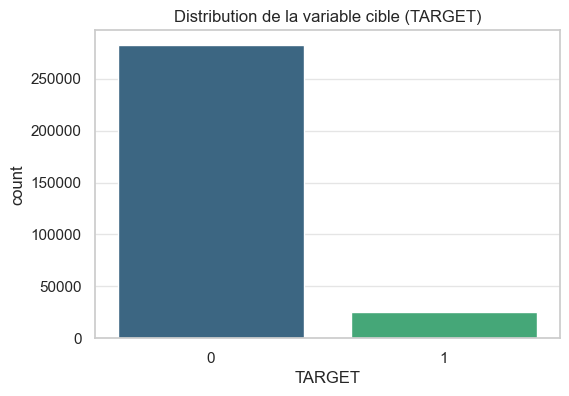

In [4]:
target_counts = app_train['TARGET'].value_counts(normalize=True) * 100
print(f"Distribution de la cible :\n{target_counts}")

plt.figure(figsize=(6, 4))
sns.countplot(x='TARGET', data=app_train, palette='viridis')
plt.title('Distribution de la variable cible (TARGET)')
plt.show()

### 5.2 Valeurs manquantes

On visualise les données manquantes avec `missingno`.

Visualisation des valeurs manquantes pour app_train (échantillon) :


<Axes: >

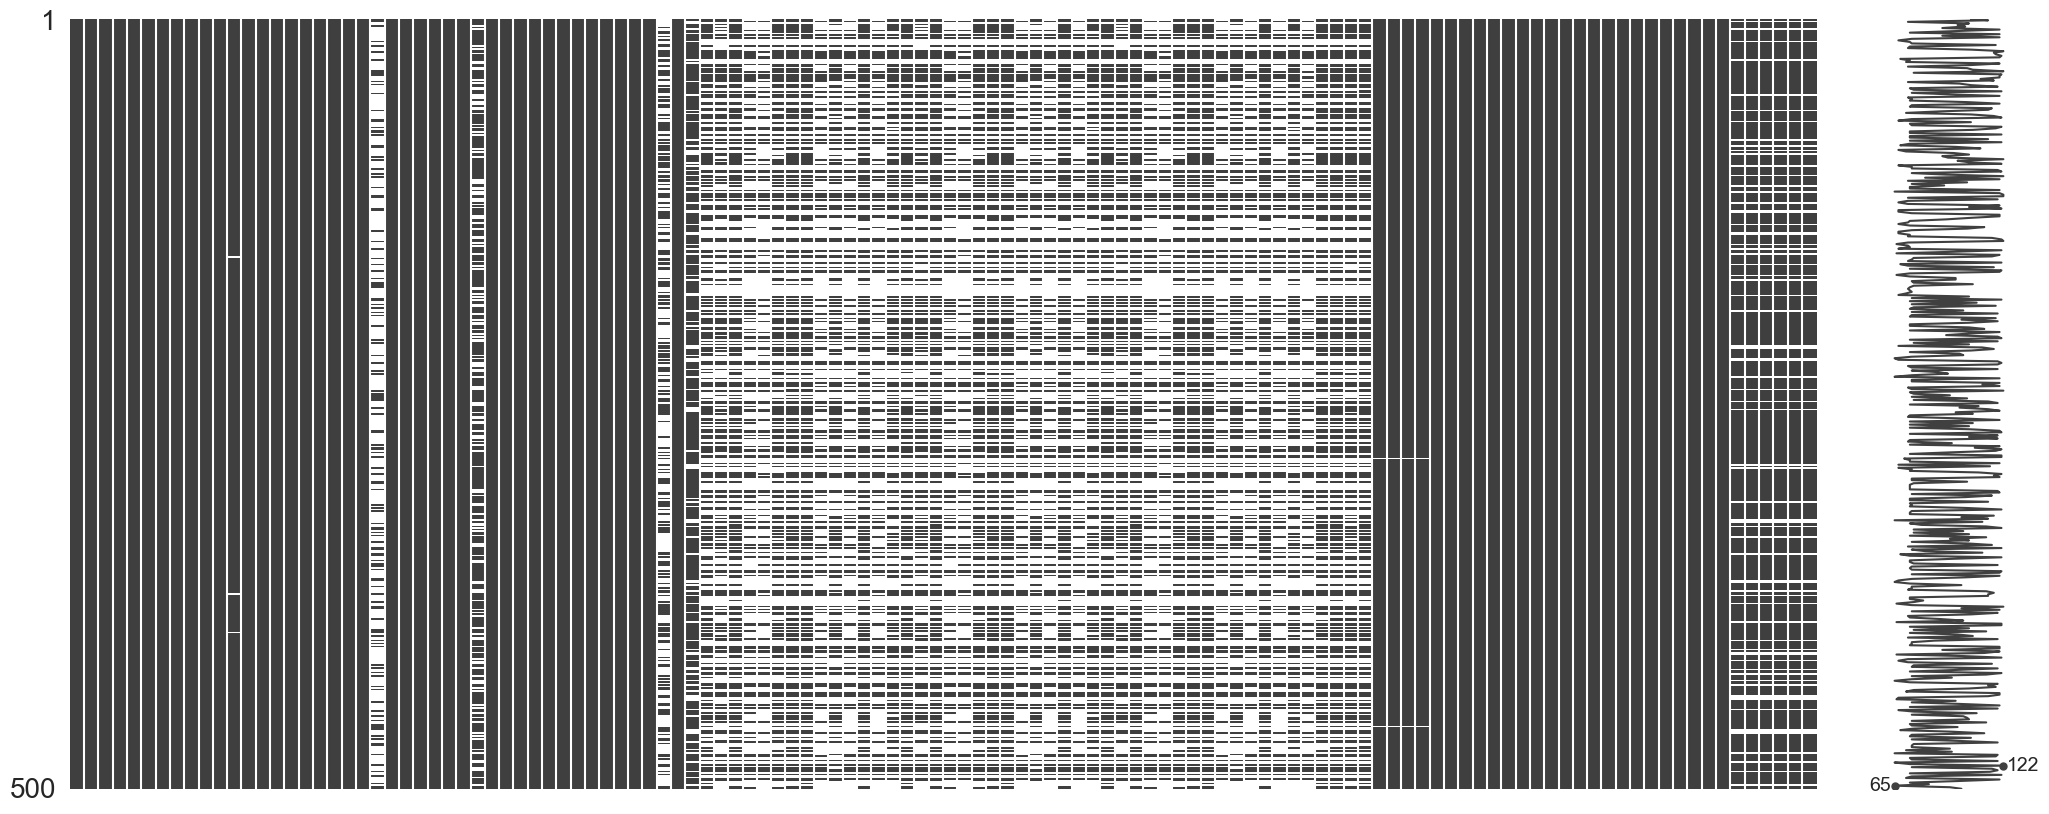

In [5]:
print("Visualisation des valeurs manquantes pour app_train (échantillon) :")
msno.matrix(app_train.sample(500))

### 5.3 Détection et traitement des anomalies

On traite la valeur aberrante 365243 dans `DAYS_EMPLOYED` qui correspond probablement à une erreur de saisie pour "non employé".

In [6]:
for df in [app_train, app_test]:
    df['DAYS_EMPLOYED_ANOM'] = df["DAYS_EMPLOYED"] == 365243
    df['DAYS_EMPLOYED'].replace({365243: np.nan}, inplace = True)

print('On a traité les anomalies de DAYS_EMPLOYED.')

On a traité les anomalies de DAYS_EMPLOYED.


## 6. Feature Engineering & Agrégations

### 6.1 Outils pour l'agrégation

Pour les tables secondaires (bureau, previous, etc.), on utilise le One-Hot Encoding **avant** l'agrégation pour capturer la fréquence des catégories par client.

In [7]:
def one_hot_encoder(df, nan_as_category = True):
    original_columns = list(df.columns)
    categorical_columns = [col for col in df.columns if df[col].dtype == 'object']
    df = pd.get_dummies(df, columns=categorical_columns, dummy_na=nan_as_category)
    new_columns = [c for c in df.columns if c not in original_columns]
    return df, new_columns

def aggregate_client_data(df, prefix):
    if 'SK_ID_CURR' in df.columns:
        group_col = 'SK_ID_CURR'
    elif 'SK_ID_BUREAU' in df.columns:
        group_col = 'SK_ID_BUREAU'
    else:
        return df
    
    numeric_df = df.select_dtypes(include=['number'])
    agg_df = numeric_df.groupby(group_col).agg(['count', 'mean', 'max', 'min', 'sum'])
    agg_df.columns = [f"{prefix}_{col[0]}_{col[1].upper()}" for col in agg_df.columns]
    return agg_df.reset_index()

### 6.2 Traitement et agrégation des tables secondaires

In [8]:
print("On lance les agrégations des tables secondaires...")

# Bureau
bureau_balance, bb_cat = one_hot_encoder(bureau_balance)
bb_agg = aggregate_client_data(bureau_balance, 'BB')
bureau, bureau_cat = one_hot_encoder(bureau)
bureau = bureau.merge(bb_agg, on='SK_ID_BUREAU', how='left')
bureau_agg = aggregate_client_data(bureau.drop(columns=['SK_ID_BUREAU']), 'BUREAU')

# Previous Applications
prev_app, prev_cat = one_hot_encoder(prev_app)
prev_agg = aggregate_client_data(prev_app, 'PREV')

# POS CASH
pos_cash, pos_cat = one_hot_encoder(pos_cash)
pos_agg = aggregate_client_data(pos_cash, 'POS')

# Installments
ins_agg = aggregate_client_data(installments, 'INS')

# Credit Card
credit_card, cc_cat = one_hot_encoder(credit_card)
cc_agg = aggregate_client_data(credit_card, 'CC')

print("Agrégations terminées.")

On lance les agrégations des tables secondaires...
Agrégations terminées.


### 6.3 Ratios métier sur Application

On crée des variables qui ont du sens d'un point de vue crédit (capacité de remboursement, etc.).

In [9]:
for df in [app_train, app_test]:
    df['DAYS_BIRTH'] = abs(df['DAYS_BIRTH'])
    df['CREDIT_INCOME_PERCENT'] = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
    df['ANNUITY_INCOME_PERCENT'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
    df['CREDIT_TERM'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']
    df['DAYS_EMPLOYED_PERCENT'] = df['DAYS_EMPLOYED'] / df['DAYS_BIRTH']

print("Ratios métier ajoutés.")

Ratios métier ajoutés.


## 7. Fusion Finale et Stratégie d'Encodage

### 7.1 Fusion
On regroupe tout dans deux DataFrames (train et test).

In [10]:
def merge_all(main_df):
    df = main_df.merge(bureau_agg, on='SK_ID_CURR', how='left')
    df = df.merge(prev_agg, on='SK_ID_CURR', how='left')
    df = df.merge(pos_agg, on='SK_ID_CURR', how='left')
    df = df.merge(ins_agg, on='SK_ID_CURR', how='left')
    df = df.merge(cc_agg, on='SK_ID_CURR', how='left')
    return df

train_merged = merge_all(app_train)
test_merged = merge_all(app_test)

print(f"Dimensions après fusion - Train: {train_merged.shape}, Test: {test_merged.shape}")

Dimensions après fusion - Train: (307511, 482), Test: (48744, 481)


### 7.2 Réflexion sur l'Encodage

À ce stade, nous avons encore des variables catégorielles (type `object`). Le choix de l'encodage dépend du modèle :
1. **Modèles de Boosting (LightGBM, XGBoost, CatBoost)** : Ils gèrent très bien les catégories. LightGBM peut même utiliser les catégories directement si on les transforme en type `category`.
2. **Modèles Linéaires / MLP / SVM** : Nécessitent impérativement du One-Hot Encoding (OHE) et souvent une normalisation.
3. **Random Forest (Sklearn)** : Nécessite un encodage numérique (LabelEncoding ou OHE).

**Notre choix pour l'étape d'EDA** :
On réalise un encodage minimal pour permettre une première analyse de corrélation, mais on garde la possibilité de changer plus tard.
* **Label Encoding** : Pour les variables binaires (2 catégories).
* **One-Hot Encoding** : Pour les variables avec plus de 2 catégories (optionnel ici, ou fait juste pour l'analyse).

In [11]:
# On identifie les colonnes binaires et les colonnes à plusieurs catégories
le = LabelEncoder()
le_count = 0

for col in train_merged.columns:
    if train_merged[col].dtype == 'object':
        if len(list(train_merged[col].unique())) <= 2:
            # On applique le Label Encoding pour les variables binaires
            train_merged[col] = le.fit_transform(train_merged[col].astype(str))
            test_merged[col] = le.transform(test_merged[col].astype(str))
            le_count += 1
            
print(f'{le_count} colonnes ont été encodées par Label Encoding.')

# Pour les autres colonnes 'object', on les laisse telles quelles pour le moment
# ou on prépare une version 'dummies' pour l'analyse de corrélation.
print("Colonnes catégorielles restantes :", [col for col in train_merged.columns if train_merged[col].dtype == 'object'])

3 colonnes ont été encodées par Label Encoding.
Colonnes catégorielles restantes : ['CODE_GENDER', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


## 8. Corrélations préliminaires

On regarde quelles variables sont les plus corrélées à la cible.

In [12]:
# Pour la corrélation, on utilise uniquement les colonnes numériques
correlations = train_merged.select_dtypes(include=[np.number]).corr()['TARGET'].sort_values()

print('Corrélations les plus positives :\n', correlations.tail(10))
print('\nCorrélations les plus négatives :\n', correlations.head(10))

Corrélations les plus positives :
 CC_AMT_RECIVABLE_MEAN                0.086478
CC_AMT_TOTAL_RECEIVABLE_MEAN         0.086490
CC_AMT_BALANCE_MEAN                  0.087177
BUREAU_BB_MONTHS_BALANCE_MIN_MEAN    0.089038
BUREAU_DAYS_CREDIT_MEAN              0.089729
CC_CNT_DRAWINGS_CURRENT_MAX          0.101389
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN     0.107692
TARGET                               1.000000
CC_SK_DPD_MIN                             NaN
CC_SK_DPD_DEF_MIN                         NaN
Name: TARGET, dtype: float64

Corrélations les plus négatives :
 EXT_SOURCE_3                          -0.178919
EXT_SOURCE_2                          -0.160472
EXT_SOURCE_1                          -0.155317
BUREAU_BB_MONTHS_BALANCE_COUNT_MEAN   -0.080193
DAYS_BIRTH                            -0.078239
BUREAU_BB_MONTHS_BALANCE_COUNT_MAX    -0.068792
CC_SK_DPD_DEF_COUNT                   -0.060481
CC_AMT_TOTAL_RECEIVABLE_COUNT         -0.060481
CC_AMT_CREDIT_LIMIT_ACTUAL_COUNT      -0.060481
CC_AMT_B

## 9. Sauvegarde

On sauvegarde les résultats. Le format Parquet conservera les colonnes 'object' intactes.

In [13]:
if not os.path.exists('../outputs'):
    os.makedirs('../outputs')

# On sauvegarde avec les types actuels
train_merged.to_parquet('../outputs/train_final.parquet')
test_merged.to_parquet('../outputs/test_final.parquet')

print("Datasets sauvegardés dans outputs/.")

Datasets sauvegardés dans outputs/.
